# Лабораторная работа №7: Массовое моделирование доверительных интервалов для среднего и медианы

**Задание.**
1. Генерировать выборки разного размера из распределений $N(0, 2^2)$, $U[-1, 1]$ и $Exp(1) - 1$ (сдвинутое экспоненциальное с $\mu = 0$).
   По каждой выборке построить доверительные интервалы для математического ожидания: асимптотический, Стьюдента, Холла (bootstrap) и непараметрический интервал для **медианы**.
2. Для $n = 10, 20, 30, 50, 60$ сгенерировать по $N = 10^3$ выборок, посчитать долю $Q^*$, накрывших истинное $\mu = 0$, сравнить с назначенной $Q = 0{,}95$. На графиках — доверительные коридоры вокруг каждой точки $Q^*$.

## Теория

Есть выборка $X_1,\ldots,X_n$ с $M[X_i]=\mu$. Строим доверительные интервалы для **среднего** тремя способами и отдельно — для **медианы**. На графиках п. 1 — примеры интервалов по 50 выборкам; п. 2 — доля $Q^*$ накрытий $\mu=0$ по $N=10^3$ симуляциям.

Общие величины: $\bar x=\frac1n\sum X_i$, $s=\sqrt{\frac{1}{n-1}\sum(X_i-\bar x)^2}$.

### 1. Асимптотический (нормальный) ДИ для $\mu$

**Смысл:** по ЦПТ $\bar x$ почти нормально, вместо $\sigma$ подставляем $s$ и квантиль $u$ стандартного нормального:

$$
\bar x \pm u_{(1+Q)/2}\,\frac{s}{\sqrt{n}}.
$$

Удобен при больших $n$; для нормальной выборки при малых $n$ часто **занижает** покрытие (на графиках п. 2 точки $Q^*$ могут висеть ниже 0,95).

### 2. Интервал Стьюдента

Для $N(\mu,\sigma^2)$ статистика $(\bar x-\mu)/(s/\sqrt{n})\sim t_{n-1}$, интервал

$$
\bar x \pm t_{(1+Q)/2,\,n-1}\,\frac{s}{\sqrt{n}}
$$

даёт ровно $Q$ при нормальности — на графиках для $N(0,2^2)$ точки $Q^*$ ближе всего к горизонтали 0,95.

### 3. Bootstrap Холла

Пересэмплируем выборку с возвращением, смотрим разброс $\bar x^*-\bar x$ и отражаем квантили относительно $\bar x$. Даёт гибкость без формулы, но при малых $n$ перцентили иногда «узковаты» (на графике — просадка $Q^*$ при $n=10$).

### 4. ДИ для медианы (порядковые статистики)

Для симметричного непрерывного $F$ интервал $(X_{(r)},X_{(n-r+1)})$ накрывает **медиану** $m$ с вероятностью $\ge Q$; $r$ выбирают минимальным с этим свойством. На п. 1 четвёртая колонка — именно медианные интервалы (синий/красный по накрытию $\mu$).

**Важно для графиков п. 2:** если $\mu\neq m$ (сдвинутое $Exp(1)-1$: $m\approx-0{,}307$, $\mu=0$), линия $Q^*$ для «медианного» метода при проверке по $\mu$ **не обязана** быть около 0,95 — это видно на правой нижней панели для экспоненты.

| распределение | $\mu$ | медиана $m$ |
|---|---|---|
| $N(0,2^2)$ | $0$ | $0$ |
| $U[-1,1]$ | $0$ | $0$ |
| $Exp(1)-1$ | $0$ | $\ln 2-1\approx-0{,}307$ |



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import comb

SEED = 42
N = 10**3
Q = 0.95
B_BOOT = 999
ALPHA = 1 - Q
SIGMA_NORM = 2.0
MEDIAN_EXP = np.log(2) - 1

NS_COVER = [10, 20, 30, 50, 60]
METHODS = ['асимптот.', 'Стьюдента', 'Холла', 'медианы']
METHOD_KEYS = ['asym', 'student', 'hall', 'median']

plt.rcParams['figure.dpi'] = 110
rng = np.random.default_rng(SEED)
rng_boot = np.random.default_rng(SEED + 1)

DISTS = {
    'N(0, 2²)': dict(
        sample=lambda r, shape: r.normal(0, SIGMA_NORM, shape),
        mu=0.0,
        median=0.0,
    ),
    'U[-1, 1]': dict(
        sample=lambda r, shape: r.uniform(-1, 1, shape),
        mu=0.0,
        median=0.0,
    ),
    'Exp(1)−1': dict(
        sample=lambda r, shape: r.exponential(1, shape) - 1.0,
        mu=0.0,
        median=MEDIAN_EXP,
    ),
}


def mean_margin(x, crit):
    """crit: (N,) or scalar — critical value times s/sqrt(n)."""
    return crit * x.std(-1, ddof=1) / np.sqrt(x.shape[-1])


def ci_asymptotic(x, Q):
    n = x.shape[-1]
    c = stats.norm.ppf((1 + Q) / 2)
    h = mean_margin(x, c)
    m = x.mean(-1)
    return m - h, m + h


def ci_student(x, Q):
    n = x.shape[-1]
    c = stats.t.ppf((1 + Q) / 2, n - 1)
    h = mean_margin(x, c)
    m = x.mean(-1)
    return m - h, m + h


def ci_hall(x, Q, B=B_BOOT, rng_local=None):
    if rng_local is None:
        rng_local = rng_boot
    Ns, n = x.shape
    xbar = x.mean(axis=1)
    idx = rng_local.integers(0, n, size=(B, Ns, n))
    boot = x[np.arange(Ns)[None, :, None], idx]
    boot_mean = boot.mean(axis=2)
    shift = boot_mean - xbar[None, :]
    q_hi = np.quantile(shift, 1 - ALPHA / 2, axis=0)
    q_lo = np.quantile(shift, ALPHA / 2, axis=0)
    return xbar - q_hi, xbar - q_lo


_median_r_cache = {}


def median_r(n, Q):
    key = (n, Q)
    if key not in _median_r_cache:
        r_best = 1
        for r in range(1, n // 2 + 1):
            if n - r + 1 <= r:
                break
            prob = sum(comb(n, j, exact=True) for j in range(r, n - r + 1)) / (2 ** n)
            if prob >= Q:
                r_best = r
            else:
                break
        _median_r_cache[key] = r_best
    return _median_r_cache[key]


def ci_median(x, Q):
    n = x.shape[-1]
    r = median_r(n, Q)
    xs = np.sort(x, axis=-1)
    lo = xs[:, r - 1]
    hi = xs[:, n - r]
    return lo, hi


CI_FUNCS = {
    'asym': ci_asymptotic,
    'student': ci_student,
    'hall': ci_hall,
    'median': ci_median,
}


def covers(lo, hi, target):
    return (lo < target) & (target < hi)


def binomial_band(q_hat, N_sim, z=1.96):
    se = np.sqrt(np.clip(q_hat * (1 - q_hat) / N_sim, 0, None))
    return q_hat - z * se, q_hat + z * se


## 1. Примеры доверительных интервалов ($n = 20$, $Q = 0{,}95$)

По 50 выборкам каждого распределения. Синим — интервалы, накрывшие $\mu = 0$; красным — промах. Для метода медианы проверяем накрытие $\mu$ (как в п. 2 задания).

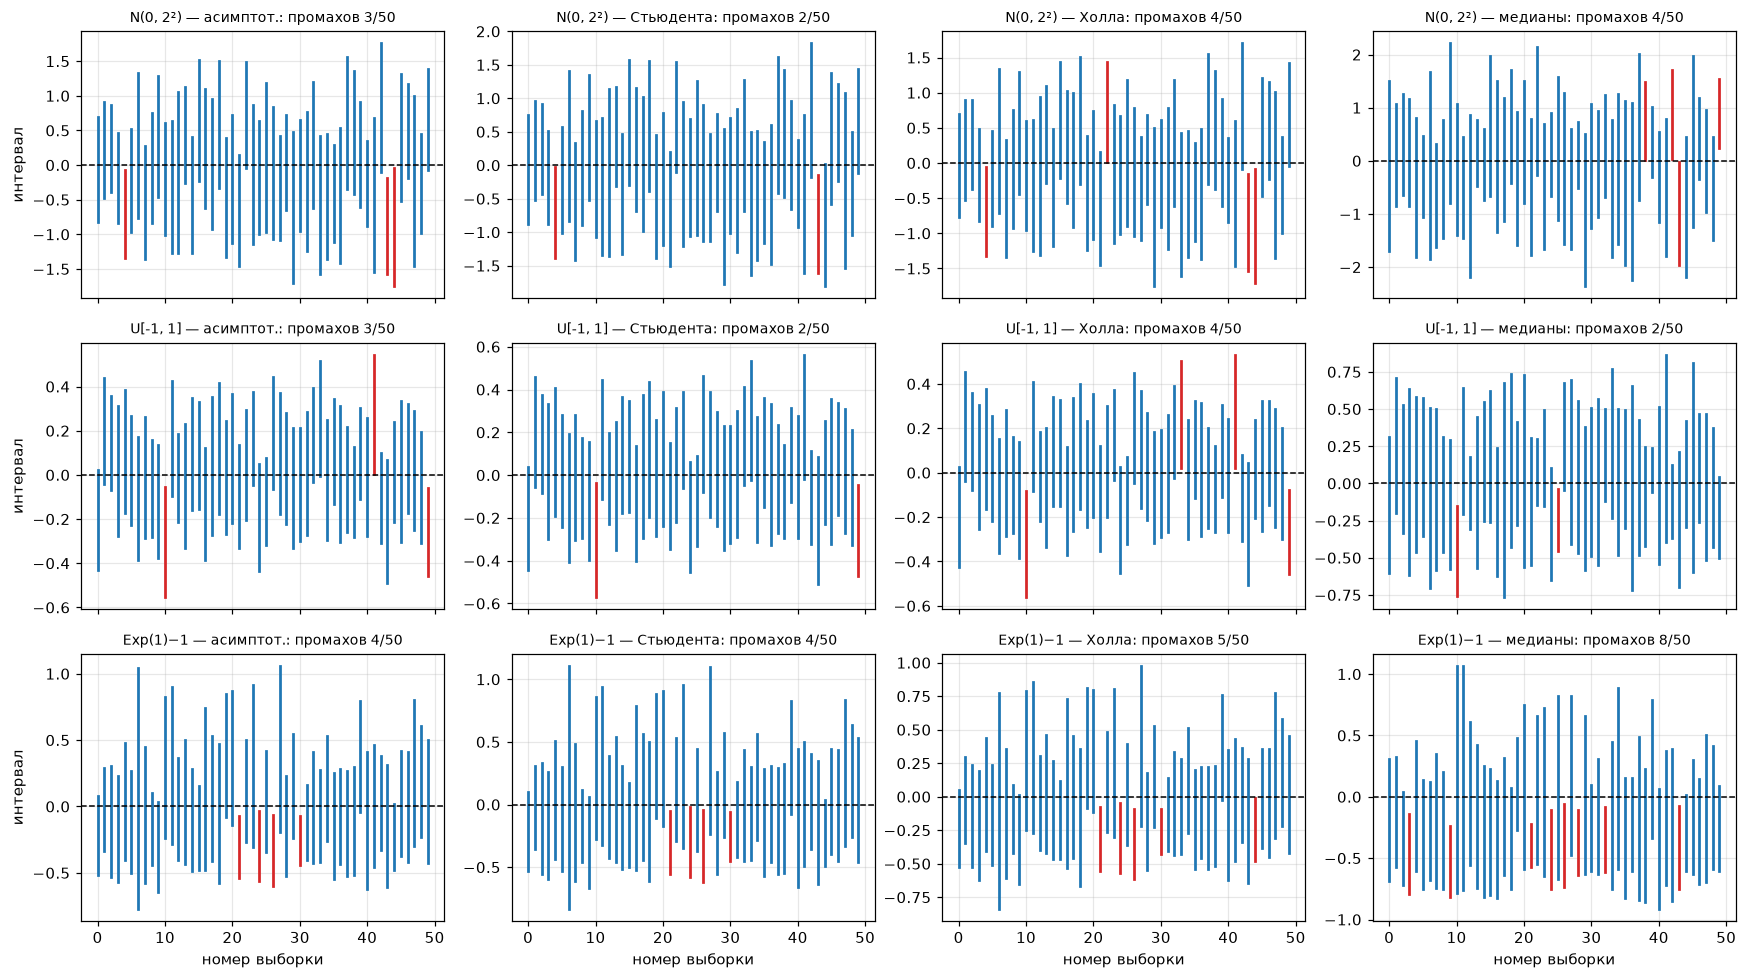

In [2]:
n_demo = 20
n_show = 50

fig, axes = plt.subplots(len(DISTS), len(METHODS), figsize=(16, 9), sharex='col')
for i, (dname, d) in enumerate(DISTS.items()):
  x = d['sample'](rng, (n_show, n_demo))
  for j, key in enumerate(METHOD_KEYS):
    lo, hi = CI_FUNCS[key](x, Q)
    miss = ~covers(lo, hi, d['mu'])
    ax = axes[i, j]
    for k in range(n_show):
      col = 'tab:red' if miss[k] else 'tab:blue'
      ax.plot([k, k], [lo[k], hi[k]], color=col, lw=1.8)
    ax.axhline(d['mu'], color='black', ls='--', lw=1)
    ax.set_title(f'{dname} — {METHODS[j]}: промахов {miss.sum()}/{n_show}', fontsize=9)
    if i == len(DISTS) - 1:
      ax.set_xlabel('номер выборки')
    if j == 0:
      ax.set_ylabel('интервал')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 2. Реальная доверительная вероятность $Q^*$ при назначенной $Q = 0{,}95$

По $N = 10^3$ выборок для каждой пары (распределение, $n$) считаем долю интервалов, содержащих **$\mu = 0$** (для всех четырёх методов, включая интервал медианы). Вокруг каждой точки $Q^*$ — нормальное приближение биномиального коридора $\hat Q \pm 1{,}96\sqrt{\hat Q(1-\hat Q)/N}$. Горизонтальная линия — назначенные $0{,}95$.

In [3]:
coverage = {
    dname: {key: [] for key in METHOD_KEYS}
    for dname in DISTS
}
coverage_median_target = {dname: {key: [] for key in ['median']} for dname in DISTS}

for dname, d in DISTS.items():
    for n in NS_COVER:
        x = d['sample'](rng, (N, n))
        for key in METHOD_KEYS:
            lo, hi = CI_FUNCS[key](x, Q)
            coverage[dname][key].append(covers(lo, hi, d['mu']).mean())
        lo, hi = ci_median(x, Q)
        coverage_median_target[dname]['median'].append(covers(lo, hi, d['median']).mean())

print(f'Доля накрытий μ = 0 (N = {N}, Q = {Q})')
header = f'{"n":>5}' + ''.join(f'{m:>14}' for m in METHODS)
for dname in DISTS:
    print(f'\n{dname}')
    print(header)
    for i, n in enumerate(NS_COVER):
        row = f'{n:>5}' + ''.join(f'{coverage[dname][k][i]:>14.3f}' for k in METHOD_KEYS)
        print(row)

print('\nДоля накрытий истинной медианы (только интервал медианы)')
print(f'{"n":>5}' + ''.join(f'{dn:>14}' for dn in DISTS))
for i, n in enumerate(NS_COVER):
    print(f'{n:>5}' + ''.join(f'{coverage_median_target[dn]["median"][i]:>14.3f}' for dn in DISTS))


Доля накрытий μ = 0 (N = 1000, Q = 0.95)

N(0, 2²)
    n     асимптот.     Стьюдента         Холла       медианы
   10         0.924         0.953         0.906         0.975
   20         0.955         0.967         0.945         0.965
   30         0.937         0.946         0.930         0.965
   50         0.950         0.957         0.949         0.970
   60         0.945         0.949         0.944         0.963

U[-1, 1]
    n     асимптот.     Стьюдента         Холла       медианы
   10         0.908         0.941         0.878         0.978
   20         0.931         0.945         0.920         0.956
   30         0.942         0.952         0.932         0.952
   50         0.946         0.953         0.943         0.960
   60         0.949         0.959         0.947         0.975

Exp(1)−1
    n     асимптот.     Стьюдента         Холла       медианы
   10         0.858         0.887         0.827         0.918
   20         0.913         0.921         0.896         0.828

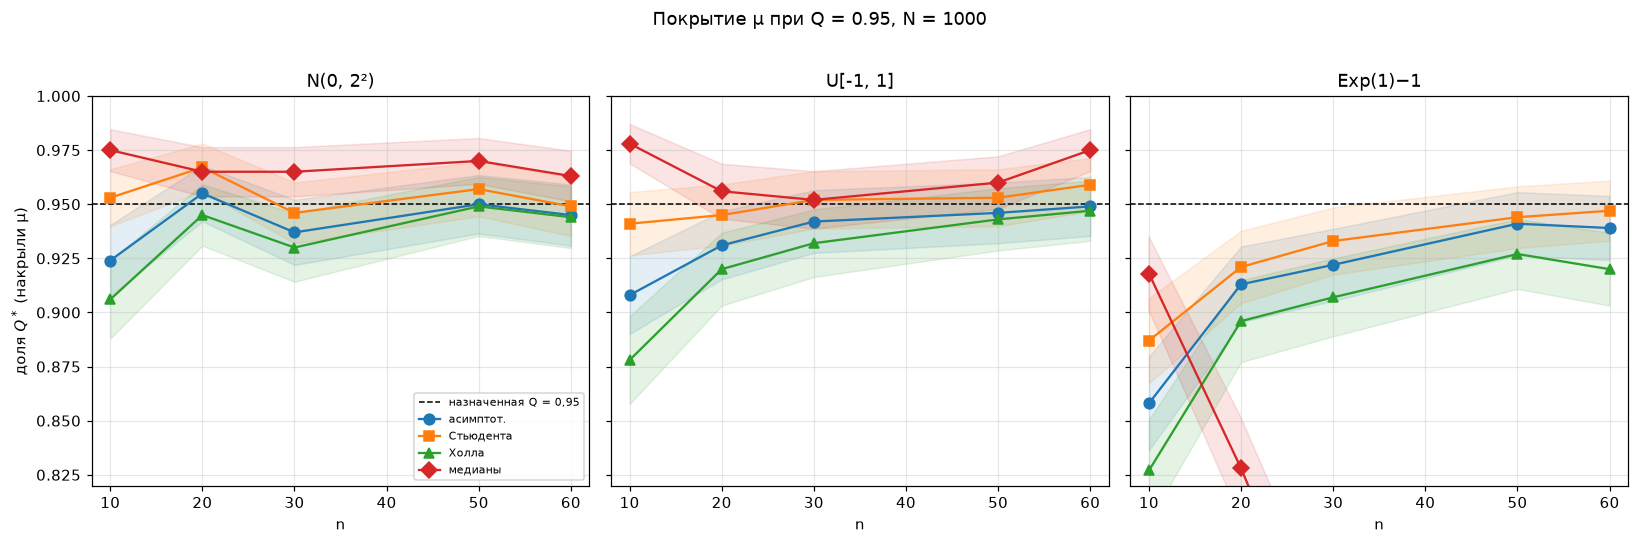

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
colors = {'asym': 'tab:blue', 'student': 'tab:orange', 'hall': 'tab:green', 'median': 'tab:red'}
markers = {'asym': 'o', 'student': 's', 'hall': '^', 'median': 'D'}

for ax, (dname, cov_d) in zip(axes, coverage.items()):
    ax.axhline(Q, color='black', ls='--', lw=1, label='назначенная Q = 0,95')
    for key, label in zip(METHOD_KEYS, METHODS):
        q_hat = np.array(cov_d[key])
        lo_b, hi_b = binomial_band(q_hat, N)
        ax.fill_between(NS_COVER, lo_b, hi_b, color=colors[key], alpha=0.12)
        ax.plot(NS_COVER, q_hat, marker=markers[key], ms=7, color=colors[key], label=label)
    ax.set(xlim=(8, 62), ylim=(0.82, 1.0), xlabel='n', title=dname)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('доля $Q^*$ (накрыли μ)')
axes[0].legend(fontsize=7, loc='lower right')
plt.suptitle(f'Покрытие μ при Q = {Q}, N = {N}', y=1.02)
plt.tight_layout()
plt.show()


### Выводы

**П. 1, три ряда по 50 интервалов ($n=20$).** Видно, как методы дают разную «толщину» веера: у Стьюдента и асимптотического интервалы сопоставимы; bootstrap чуть уже/шире в хвостах; медианный интервал — другая геометрия (часто короче по оси, но центрирован около медианы). Красные полоски — промахи по $\mu=0$; их мало и примерно поровну между распределениями, кроме экспоненты, где асимметрия сдвигает среднее.

**П. 2, графики $Q^*$ от $n$.** Горизонталь 0,95 и серые коридоры задают эталон; сравниваем, где проходят кривые методов.

*$N(0,2^2)$.* Кривая **Стьюдента** почти на 0,95 (среднее 0,954, при $n=60$ — 0,949). **Асимптотика** при $n=10$ проваливается до 0,924, в среднем 0,942 — на левом краю графика заметен зазор под 0,95. **Холл** при $n=10$ — 0,906, в среднем 0,935. **Медиана** (проверка по $\mu$) — выше 0,95 (0,968 в среднем): при $\mu=m=0$ интервал для медианы шире относительно нуля, чем нужно для среднего.

*$U[-1,1]$.* Картина та же: Стьюдента ≈0,950, асимптотика и Холл чуть ниже, особенно при малых $n$ (Холл 0,878 при $n=10$).

*$Exp(1)-1$.* Все ДИ **для среднего** слегка недотягивают до 0,95 (Стьюдента 0,926 в среднем, к $n=60$ — 0,947). Кривая **медианы** при проверке $\mu$ на среднем и правом графиках уходит вниз (0,553 при $n=60$) — интервал накрывает $m\approx-0{,}307$, а не 0.

При $N=10^3$ погрешность $\hat Q$ около $\pm 0{,}014$.

**Итог по рисункам:** для оценки $\mu$ на графиках лучше всего держится Стьюдента; асимптотика и bootstrap догоняют при росте $n$. Медианный интервал на панелях с экспонентой наглядно показывает: метод для медианы нельзя читать как ДИ для среднего, когда $\mu\neq m$.



In [5]:
def summarize(name, keys=None):
    if keys is None:
        keys = METHOD_KEYS
    cov = coverage[name]
    means = {k: np.mean(cov[k]) for k in keys}
    at60 = {k: cov[k][-1] for k in keys}
    return means, at60


norm_mean, norm60 = summarize('N(0, 2²)')
exp_mean, exp60 = summarize('Exp(1)−1')
uni_mean, _ = summarize('U[-1, 1]')

band_ref = 1.96 * np.sqrt(Q * (1 - Q) / N)
print(f'Точность оценки доли (±): {band_ref:.3f}')
print()
print('Средняя доля накрытий μ по n = 10,…,60:')
for label, d in [('N(0,2²)', norm_mean), ('U[-1,1]', uni_mean), ('Exp(1)−1', exp_mean)]:
    print(f'  {label}:', ', '.join(f'{METHODS[i]}={d[METHOD_KEYS[i]]:.3f}' for i in range(4)))
print()
print('При n = 60:')
print(f'  N(0,2²): асимпт. {norm60["asym"]:.3f}, Стьюдента {norm60["student"]:.3f}, '
      f'Холла {norm60["hall"]:.3f}, медианы (по μ) {norm60["median"]:.3f}')
print(f'  Exp(1)−1: асимпт. {exp60["asym"]:.3f}, Стьюдента {exp60["student"]:.3f}, '
      f'Холла {exp60["hall"]:.3f}, медианы (по μ) {exp60["median"]:.3f}')
print()
med60 = {dn: coverage_median_target[dn]['median'][-1] for dn in DISTS}
print('Покрытие истинной медианы интервалом медианы при n=60:')
for dn, v in med60.items():
    print(f'  {dn}: {v:.3f}')


Точность оценки доли (±): 0.014

Средняя доля накрытий μ по n = 10,…,60:
  N(0,2²): асимптот.=0.942, Стьюдента=0.954, Холла=0.935, медианы=0.968
  U[-1,1]: асимптот.=0.935, Стьюдента=0.950, Холла=0.924, медианы=0.964
  Exp(1)−1: асимптот.=0.915, Стьюдента=0.926, Холла=0.895, медианы=0.719

При n = 60:
  N(0,2²): асимпт. 0.945, Стьюдента 0.949, Холла 0.944, медианы (по μ) 0.963
  Exp(1)−1: асимпт. 0.939, Стьюдента 0.947, Холла 0.920, медианы (по μ) 0.553

Покрытие истинной медианы интервалом медианы при n=60:
  N(0, 2²): 0.963
  U[-1, 1]: 0.975
  Exp(1)−1: 0.975
